# Checkpoint — KMeans & DBSCAN

Dit notebook wordt automatisch gecheckt via pytest (GitHub Actions). De checks voeren je notebook uit en valideren of bepaalde variabelen bestaan en binnen de verwachte ranges vallen. **Je krijgt geen hints in de foutmeldingen: het is aan jou om correct werkende code te schrijven.**

## BELANGRIJK: gebruik exact de genoemde variabelennamen

De checks zoeken volgende variabelen in je notebook. Andere namen worden niet gezien:

- `best_k_wine` — de gekozen waarde van k voor de Wine-dataset (int)
- `silhouette_wine` — de silhouette score van die keuze (float)
- `image` — de ingeladen afbeelding (3D numpy-array)
- `n_colors` — het tuple van aantal kleuren `(10, 8, 6, 4, 2)`
- `segmented_imgs` — de lijst van gesegmenteerde afbeeldingen (5 elementen, zelfde vorm als `image`)
- `best_k_iris` — de gekozen waarde van k voor de Iris-dataset (int)
- `silhouette_iris` — de silhouette score van die keuze (float)
- `best_k_mall` — de gekozen waarde van k voor de Mall-dataset (int)
- `silhouette_mall` — de silhouette score van die keuze (float)
- `antwoord_iris` — meerkeuzevraag 1: `"A"`, `"B"`, `"C"` of `"D"`
- `antwoord_dbscan` — meerkeuzevraag 2: `"A"`, `"B"`, `"C"` of `"D"`

Gebruik overal `random_state=42` (en `n_init=10`) bij KMeans zodat je resultaten reproduceerbaar zijn en binnen de verwachte drempels vallen. Werk met de lokale afbeelding `images/butterfly.jpg` (er wordt niets gedownload).

## Oefening 1 — Wijn

Cluster de Wine-dataset zo optimaal mogelijk met KMeans. De dataset heeft 13 features op verschillende schalen, dus **schaal eerst met `StandardScaler`**.

Probeer verschillende waarden van `k`, bereken telkens de **silhouette score** en kies de `k` met de hoogste score.

Bewaar je keuze in `best_k_wine` en de bijhorende score in `silhouette_wine`.

In [2]:
import numpy as np
from sklearn import datasets
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

wine = datasets.load_wine()
data = wine.data

# Schaal de data zodat alle features gelijk gewicht krijgen
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

K = 2 | score = 0.2593
K = 3 | score = 0.2849
K = 4 | score = 0.2602
K = 5 | score = 0.2016
K = 6 | score = 0.2372
K = 7 | score = 0.2036

Beste resultaat: k = 3 | score: 0.2849



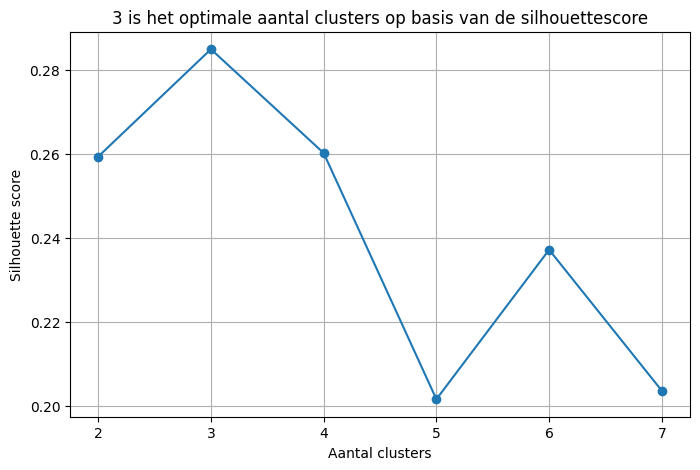

In [8]:
# TODO: bereken voor elke k in range(2, 8) de silhouette score (KMeans met
# random_state=42, n_init=10). Bewaar de k met de hoogste score in best_k_wine
# en die score in silhouette_wine.
k_values = range(2,8)
scores = []
best_k_wine = 2
silhouette_wine = 0

for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    y_pred = kmeans.fit_predict(data_scaled)
    score = silhouette_score(data_scaled, kmeans.labels_)
    print(f"K = {k} | score = {score:.4f}")
    scores.append(score)
    if score > silhouette_wine:
        silhouette_wine = score
        best_k_wine = k

print()
print(f"Beste resultaat: k = {best_k_wine} | score: {silhouette_wine:.4f}")
print()
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(k_values, scores, marker='o', linestyle='-')
plt.title('3 is het optimale aantal clusters op basis van de silhouettescore')
plt.xlabel('Aantal clusters')
plt.ylabel('Silhouette score')
plt.grid(True)
plt.show()

## Oefening 2 — Image Segmentation

We gebruiken clustering om een afbeelding in stukken met gelijkaardige kleuren te verdelen. Gebruik de lokale afbeelding `images/butterfly.jpg` (533×800 pixels, 3 kleurkanalen).

Hervorm de 3D-array tot een `(n_pixels, 3)` matrix met `reshape(-1, 3)`, train dan KMeans met `n_clusters` in `(10, 8, 6, 4, 2)` en vervang elke pixel door de centroidkleur van zijn cluster. Hervorm het resultaat terug naar de originele vorm.

Bewaar het tuple `n_colors = (10, 8, 6, 4, 2)` en de 5 gesegmenteerde afbeeldingen in `segmented_imgs`.

In [9]:
import numpy as np
from PIL import Image
from sklearn.cluster import KMeans

# Gebruik het lokale voorbeeldbeeld (geen download nodig)
image = np.asarray(Image.open('images/butterfly.jpg'))
print('image shape:', image.shape)

# Hervorm de 3D-array (pixels, breedte, kanalen) naar een (n_pixels, 3) matrix
X = image.reshape(-1, 3)

image shape: (533, 800, 3)


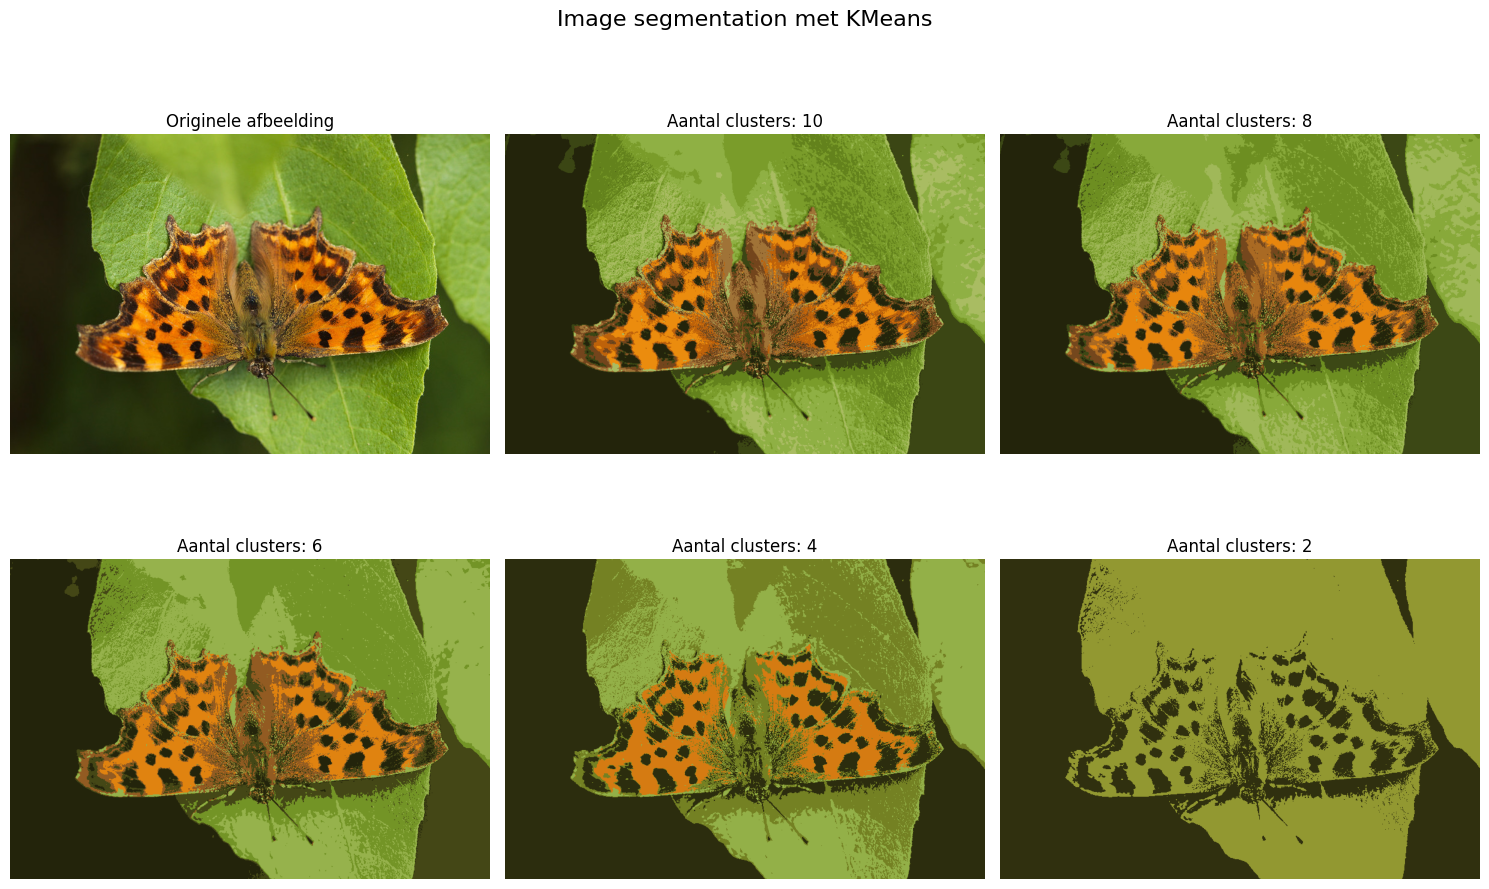

In [ ]:
# TODO: train voor elk aantal kleuren een KMeans (random_state=42, n_init=10)
# op X, vervang elke pixel door de centroidkleur van zijn cluster en hervorm
# terug naar image.shape.
# Bewaar het tuple n_colors = (10, 8, 6, 4, 2) en de 5 gesegmenteerde
# afbeeldingen in segmented_imgs (zelfde vorm als image).
n_colors = (10, 8, 6, 4, 2)
segmented_imgs = []
for k in n_colors:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    segmented_img = kmeans.cluster_centers_[kmeans.labels_]
    segmented_imgs.append(segmented_img.reshape(image.shape))


import matplotlib.pyplot as plt
import numpy as np

# Maak de grid van 2 rijen en 3 kolommen
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Image segmentation met KMeans', fontsize=16)

# Maak van de 2D-array van assen een 1D-lijst om er makkelijk over te itereren
axes = axes.flatten()

# Toon de originele afbeelding in de eerste subplot
axes[0].imshow(image)
axes[0].set_title('Originele afbeelding')
axes[0].axis('off') # Assen verbergen voor een mooiere weergave

# Toon de gesegmenteerde afbeeldingen in de overige subplots
for i, (k, seg_img) in enumerate(zip(n_colors, segmented_imgs)):
    # We gebruiken index i+1 omdat index 0 al bezet is door de originele afbeelding.
    # We casten naar np.uint8 zodat matplotlib de kleuren correct interpreteert.
    axes[i+1].imshow(seg_img.astype(np.uint8))
    axes[i+1].set_title(f'Aantal clusters: {k}')
    axes[i+1].axis('off')

plt.tight_layout()
plt.show()

## Oefening 3 — KMeans vs DBSCAN op Iris

De Iris-dataset bevat 3 soorten die in de feature-ruimte goed gescheiden, **bolvormige** clusters van **gelijkaardige dichtheid** vormen.

Pas zowel KMeans (verschillende `k`) als DBSCAN (verschillende `eps`/`min_samples`) toe op de **gestandaardiseerde** data en vergelijk met de silhouette score. Bewaar je gekozen `k` in `best_k_iris` en de hoogste silhouette in `silhouette_iris`. Beantwoord daarna vraag 1 in `antwoord_iris`.

KMeans:
K = 2 | score = 0.5818
K = 3 | score = 0.4599
K = 4 | score = 0.3869
K = 5 | score = 0.3459

Beste resultaat: k = 2 | score: 0.5818



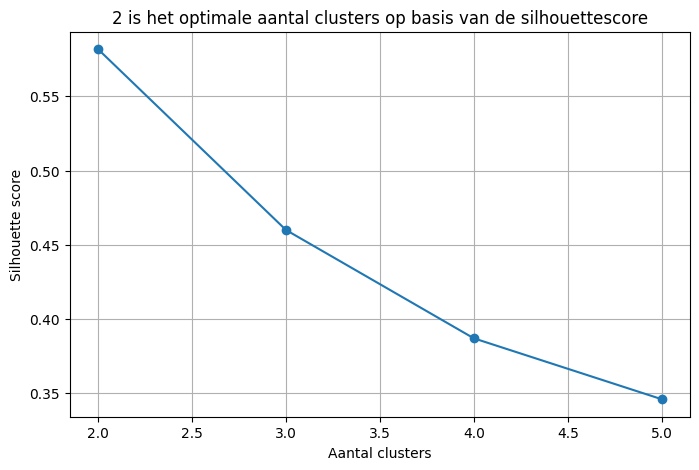


Beste resultaat: eps = 1.05 | min_samples = 4 | score: 0.5518

KMeans geeft hier een beter resultaat (silhouettescore: 0.5817500491982808)


In [22]:
# TODO: pas KMeans toe voor k in range(2, 6) en DBSCAN voor een aantal
# (eps, min_samples) combinaties, en vergelijk de silhouette scores.
# Bewaar de gekozen k in best_k_iris en de hoogste silhouette in silhouette_iris.
from sklearn.cluster import DBSCAN

iris = datasets.load_iris()
data = iris.data

scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

k_values = range(2,6)
kmeans_scores = []
silhouette_iris = -1
best_k_iris = 2
best_score_k = silhouette_iris

print("KMeans:")
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    y_pred = kmeans.fit_predict(data_scaled)
    score = silhouette_score(data_scaled, kmeans.labels_)
    kmeans_scores.append(score)
    print(f"K = {k} | score = {score:.4f}")
    if score > best_score_k:
        best_score_k = score
        best_k_iris = k

print()
print(f"Beste resultaat: k = {best_k_iris} | score: {best_score_k:.4f}")
print()

plt.figure(figsize=(8, 5))
plt.plot(k_values, kmeans_scores, marker='o', linestyle='-')
plt.title(f'{best_k_iris} is het optimale aantal clusters op basis van de silhouettescore')
plt.xlabel('Aantal clusters')
plt.ylabel('Silhouette score')
plt.grid(True)
plt.show()

best_score_DB = silhouette_iris
eps_values = np.arange(0.05, 1.1, 0.05)
min_samples = range(2, 11)
best_eps = 0.05
best_samples = 2

for eps in eps_values:
    for samples in min_samples:
        dbscan = DBSCAN(eps=eps, min_samples=samples)
        y_pred = dbscan.fit_predict(data_scaled)
        try:
            score = silhouette_score(data_scaled, dbscan.labels_)
        except ValueError:
            continue
        if score > best_score_DB:
            best_score_DB = score
            best_eps = eps
            best_samples = samples

print()
print(f"Beste resultaat: eps = {best_eps} | min_samples = {best_samples} | score: {best_score_DB:.4f}")
print()
silhouette_iris = max(best_score_k, best_score_DB)
if silhouette_iris == best_score_k:
    print(f"KMeans geeft hier een beter resultaat (silhouettescore: {silhouette_iris})")
else:
    print(f"DBSCAN geeft hier een beter resultaat (silhouettescore: {silhouette_iris})")


## Oefening 4 — KMeans vs DBSCAN op Mall

De Mall-dataset (`data/Mall_Customers.csv`) bevat klanten met `Age`, `Annual Income (k$)` en `Spending Score (1-100)`. De clusters hebben **sterk verschillende dichtheden**, waardoor DBSCAN het vaak moeilijk heeft.

Pas KMeans (verschillende `k`) en DBSCAN (verschillende `eps`/`min_samples`) toe op de **gestandaardiseerde** data en vergelijk met de silhouette score. Bewaar je gekozen `k` in `best_k_mall` en de hoogste silhouette in `silhouette_mall`. Beantwoord daarna vraag 2 in `antwoord_dbscan`.

KMeans:
K = 2 | score = 0.3355
K = 3 | score = 0.3578
K = 4 | score = 0.4040
K = 5 | score = 0.4166

Beste resultaat: k = 5 | score: 0.4166



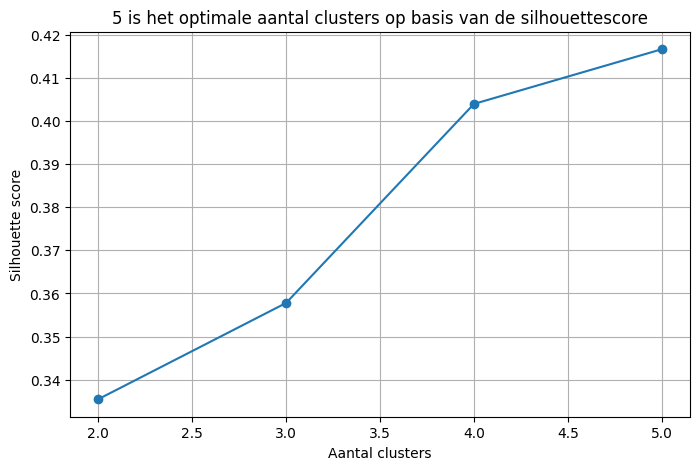


Beste resultaat: eps = 1.05 | min_samples = 10 | score: 0.3305

KMeans geeft hier een beter resultaat (silhouettescore: 0.41664341513732767)


In [24]:
# TODO: vergelijk KMeans (verschillende k's) met DBSCAN (verschillende
# eps/min_samples) via de silhouette score. Bewaar de gekozen k in best_k_mall
# en de hoogste silhouette in silhouette_mall.
import pandas as pd

mall = pd.read_csv('./data/Mall_Customers.csv')
data = mall.drop(columns=['CustomerID','Gender'])

scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

k_values = range(2,6)
kmeans_scores = []
silhouette_mall = -1
best_k_mall = 2
best_score_k = silhouette_mall

print("KMeans:")
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    y_pred = kmeans.fit_predict(data_scaled)
    score = silhouette_score(data_scaled, kmeans.labels_)
    kmeans_scores.append(score)
    print(f"K = {k} | score = {score:.4f}")
    if score > best_score_k:
        best_score_k = score
        best_k_mall = k

print()
print(f"Beste resultaat: k = {best_k_mall} | score: {best_score_k:.4f}")
print()

plt.figure(figsize=(8, 5))
plt.plot(k_values, kmeans_scores, marker='o', linestyle='-')
plt.title(f'{best_k_mall} is het optimale aantal clusters op basis van de silhouettescore')
plt.xlabel('Aantal clusters')
plt.ylabel('Silhouette score')
plt.grid(True)
plt.show()

best_score_DB = silhouette_mall
eps_values = np.arange(0.05, 1.1, 0.05)
min_samples = range(2, 11)
best_eps = 0.05
best_samples = 2

for eps in eps_values:
    for samples in min_samples:
        dbscan = DBSCAN(eps=eps, min_samples=samples)
        y_pred = dbscan.fit_predict(data_scaled)
        try:
            score = silhouette_score(data_scaled, dbscan.labels_)
        except ValueError:
            continue
        if score > best_score_DB:
            best_score_DB = score
            best_eps = eps
            best_samples = samples

print()
print(f"Beste resultaat: eps = {best_eps} | min_samples = {best_samples} | score: {best_score_DB:.4f}")
print()
silhouette_mall = max(best_score_k, best_score_DB)
if silhouette_mall == best_score_k:
    print(f"KMeans geeft hier een beter resultaat (silhouettescore: {silhouette_mall})")
else:
    print(f"DBSCAN geeft hier een beter resultaat (silhouettescore: {silhouette_mall})")


## Meerkeuzevragen

### Vraag 1 — Iris
Op de Iris-dataset haalt KMeans een veel hogere silhouette score dan DBSCAN. Wat is de belangrijkste reden?

- **A)** De clusters zijn bolvormig en hebben een gelijkaardige dichtheid, waarvoor KMeans goed geschikt is; DBSCAN kampt met de dichtheidsverschillen.
- **B)** KMeans werkt zonder features te standaardiseren.
- **C)** DBSCAN kan nooit meer dan 2 clusters vinden.
- **D)** KMeans kent het aantal clusters op voorhand, en dat is altijd beter.

Bewaar je antwoord (`"A"`, `"B"`, `"C"` of `"D"`) in `antwoord_iris`.

### Vraag 2 — DBSCAN
Wanneer is DBSCAN een betere keuze dan KMeans?

- **A)** Wanneer de clusters een onregelmatige, niet-bolvormige vorm hebben of er outliers/ruis zijn.
- **B)** Wanneer alle clusters bolvormig en even groot zijn.
- **C)** Wanneer je altijd precies `k` clusters nodig hebt.
- **D)** Wanneer de dataset klein is en je snel wilt clusteren.

Bewaar je antwoord (`"A"`, `"B"`, `"C"` of `"D"`) in `antwoord_dbscan`.

In [25]:
# Vraag 1: antwoord_iris = "A", "B", "C" of "D"
antwoord_iris = "A"

# Vraag 2: antwoord_dbscan = "A", "B", "C" of "D"
antwoord_dbscan = "A"
